# M2B · Source-derived mart exploration
Run `uv run --locked mmm-build-mart` from `modeling/` first. This notebook reads the actual ETL mart and model projection. The 120-week series is synthetic; charts describe observations and planned campaigns, not causal impact.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display
from mmm_lab.paths import DATA_DIR

mart = pq.read_table(DATA_DIR / 'marts/mart_segment_week.parquet').to_pandas()
model = pq.read_table(DATA_DIR / 'processed/model_ready.parquet').to_pandas()
quality = json.loads((DATA_DIR / 'metadata/etl_quality.json').read_text())
reconciliation = json.loads((DATA_DIR / 'metadata/etl_reconciliation.json').read_text())
assert len(mart) == len(model) == 720
assert mart.sales_units.sum() == reconciliation['source_eligible_units']
display(pd.DataFrame([quality]), pd.DataFrame([reconciliation]))

,eligible_transaction_lines,event_week_max,event_week_min,excluded_transaction_lines,exclusion_reason_counts,join_fanout_lines,null_upc_lines,product_matched_lines,source_file_submissions,source_transaction_lines,store_matched_lines
0,171741,2025-04-14,2023-01-02,0,{},0,0,171741,720,171741,171741


,excluded_source_units,mart_sales_units,planned_spend_usd_by_channel,segment_weeks_reconciled,source_eligible_units,unmatched_store_lines_outside_geography
0,0,601108,"{'coupon': 1033339.06, 'digital': 718425.25, '...",720,601108,0


## Sales trends and training boundary
The dashed line marks the first holdout week. Holdout context fields are independently simulated pre-outcome inputs; evaluation is conditional on them.

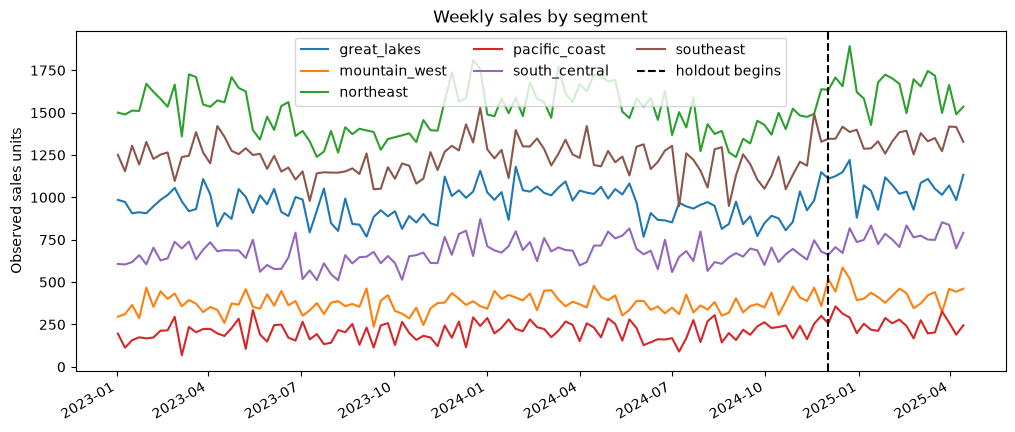

In [2]:
fig, ax = plt.subplots(figsize=(12, 5))
for segment, frame in mart.groupby('segment_id'):
    ax.plot(frame.week_start, frame.sales_units, label=segment)
boundary = mart.loc[mart.time_index.eq(101), 'week_start'].min()
ax.axvline(boundary, color='black', linestyle='--', label='holdout begins')
ax.set(ylabel='Observed sales units', title='Weekly sales by segment')
ax.legend(ncol=3)
fig.autofmt_xdate()
plt.show()

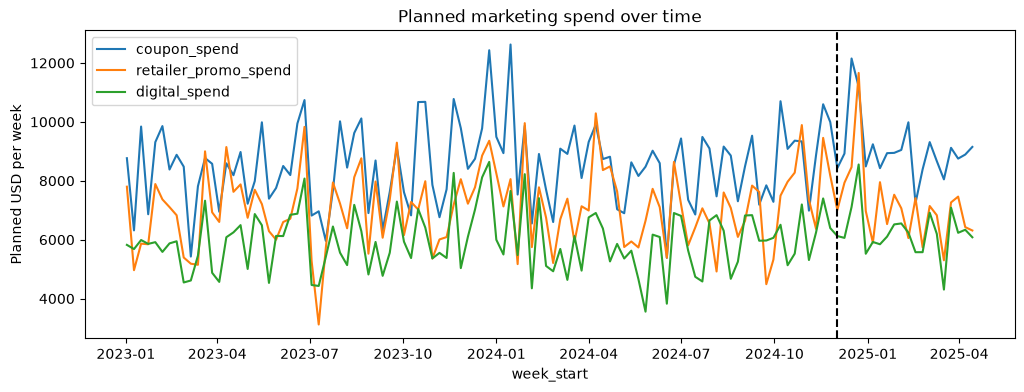

,coupon_spend,retailer_promo_spend,digital_spend
coupon_spend,1.00,0.85,0.86
retailer_promo_spend,0.85,1.00,0.86
digital_spend,0.86,0.86,1.00


In [3]:
spend_cols = ['coupon_spend', 'retailer_promo_spend', 'digital_spend']
weekly_spend = mart.groupby('week_start')[spend_cols].sum()
ax = weekly_spend.plot(figsize=(12, 4), title='Planned marketing spend over time')
ax.axvline(boundary, color='black', linestyle='--')
ax.set_ylabel('Planned USD per week')
plt.show()
display(mart[spend_cols].corr().style.format('{:.2f}'))

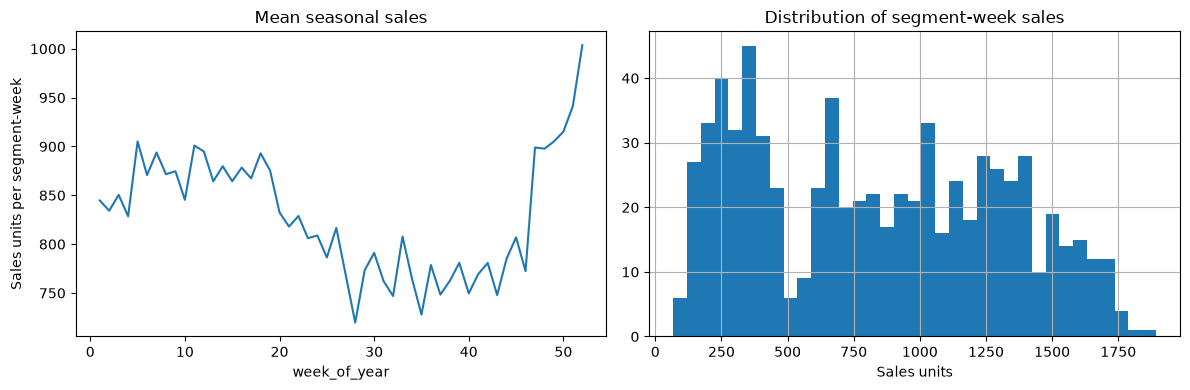

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
mart.assign(week_of_year=pd.to_datetime(mart.week_start).dt.isocalendar().week.astype(int)).groupby('week_of_year').sales_units.mean().plot(ax=axes[0], title='Mean seasonal sales')
axes[0].set_ylabel('Sales units per segment-week')
mart.sales_units.hist(ax=axes[1], bins=35)
axes[1].set(title='Distribution of segment-week sales', xlabel='Sales units')
plt.tight_layout()
plt.show()

In [5]:
summary = mart.groupby('segment_id').agg(weeks=('week_start', 'size'), mean_sales_units=('sales_units', 'mean'), total_sales_units=('sales_units', 'sum'), mean_selling_stores=('unique_selling_stores', 'mean'), total_coupon_plan_usd=('coupon_spend', 'sum'))
display(summary)
display(mart.groupby('is_holdout').agg(rows=('sales_units', 'size'), first_week=('week_start', 'min'), last_week=('week_start', 'max'), units=('sales_units', 'sum')))
assert not model.columns.str.contains('discount|truth|contribution|promo_line').any()

,weeks,mean_sales_units,total_sales_units,mean_selling_stores,total_coupon_plan_usd
segment_id,,,,,
great_lakes,120,969.008333,116281,32.316667,208352.81
mountain_west,120,381.550000,45786,18.066667,69643.66
northeast,120,1521.950000,182634,46.450000,304668.81
pacific_coast,120,213.758333,25651,11.575000,36176.01
south_central,120,681.866667,81824,26.858333,142528.01
southeast,120,1241.100000,148932,36.250000,271969.76


,rows,first_week,last_week,units
is_holdout,,,,
False,600,2023-01-02,2024-11-25,491358
True,120,2024-12-02,2025-04-14,109750


## Interpretation limits
All reference matches are complete in the default simulation. Real source extracts can contain late, revised, duplicated, or unmatched records. Missing segment-weeks fail validation rather than being turned into zero sales. `unique_selling_stores` is an observed descriptor, while `distribution_index` comes from independent pre-outcome context. Planned spend is never inferred from receipt discounts. No scaling is fitted in M2B; all prior spend weeks remain in `model_ready` for later adstock calculation. Correlated campaigns and constructed context limit causal interpretation.